# Transfer Learning: How Much Does Model Size Buy?

**P2 Notebook 3**

Notebook 2 left us a clean, split dataset of eight drum types. Here we classify it with several pretrained Keras applications of different sizes, and use them to answer the central question of this notebook: **how much does model size actually buy you on a small custom dataset?**

The Keras applications are used exactly as downloaded. The only thing we train is a tiny Keras model that maps each application's embedding vectors to our drum classes. We do not build or train a CNN from scratch.

## Learning objectives

- Choose pretrained Keras applications that span a real size range, and apply each one's own input scaling
- Balance and augment a training set in the right order, without touching the test set
- Turn images into embedding vectors with a frozen Keras application
- Train a linear probe on embeddings, using identical settings for every application so the comparison is fair
- Evaluate beyond accuracy: macro-F1, per-class recall and a confusion matrix
- Weigh accuracy against model size and embedding time

## Background

A pretrained application has already learned, from over a million ImageNet photos, which visual features matter. With `include_top=False, pooling='avg'` it turns each image into one embedding vector, a list of about a thousand numbers describing what the image contains. A **linear probe**, a single `Dense` softmax layer, then learns which of those numbers separate our classes. Because the application's weights never change, we can compute each embedding once and train the probe in seconds.

## This notebook covers

1. Choosing our Keras applications
2. Loading the data
3. The training-set pipeline: balance, then augment, then embed
4. The linear probe
5. Model 1: MobileNetV2 (small)
6. Model 2: ResNet50 (medium)
7. Model 3: EfficientNetV2M (large)
8. Comparison and discussion
9. Export

**Prerequisites:** Notebook 2 (its arrays and label-to-index mapping, in a local folder outside the repo).

**Dataset:** our cleaned drum images, already split 80/20 and stored as raw 0–255 pixels.

**Produces:** one trained probe per application in `models/`, and the label-to-index mapping next to them.

**References:** `U2-2_CNN-3_Imbalanced`, `U2-2_CNN-6_TransferLearning`, and the Keras Applications table in the assignment appendix.

**Running it:** the first run downloads each application's pretrained weights, and embedding the images with the larger applications takes minutes on a CPU. If it is too slow, lower `AUG_COPIES` in the next cell.

In [1]:
import hashlib
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, recall_score, ConfusionMatrixDisplay)

pd.set_option('display.max_columns',100)
pd.set_option('display.max_rows',100)

plt.style.use('dark_background')

import warnings
warnings.filterwarnings('ignore')

SEED = 42
keras.utils.set_random_seed(SEED)          # seeds numpy, python and the backend, so a re-run gives the same result

IMG_SIZE = 224
WEIGHTS = 'imagenet'      # the pretrained weights every application is loaded with
AUG_COPIES = 1            # augmented copies made of every training image (more = better probe, slower embedding)

# One setting set for EVERY probe (section 4). Only the input size differs.
EPOCHS = 500              # long enough for the probe's loss to level off for every application (checked in section 8.2)
BATCH_SIZE = 200
LEARNING_RATE = 0.001

PROC_DIR = Path.home() / 'MSDS565_data' / 'P2_processed'      # Notebook 2's output, outside the repo
MODELS_DIR = Path('..') / 'models'                            # this notebook lives in notebooks/, so models/ is one level up
MODELS_DIR.mkdir(exist_ok=True)

## 1. Choosing our Keras applications

We use three applications from the assignment's appendix, one from each size tier. **Params** below is the figure in the appendix, which includes the 1,000-class ImageNet classifier on top; the applications we actually use drop that classifier (`include_top=False`), so their real parameter counts, reported in section 8, are a little lower.

| Tier | Application | Params (appendix) | Weights file | Top-1 on ImageNet |
|---|---|---:|---:|---:|
| Small | `MobileNetV2` | 3.5 M | 14 MB | 71.3% |
| Medium | `ResNet50` | 25.6 M | 98 MB | 74.9% |
| Large | `EfficientNetV2M` | 54.4 M | 220 MB | 85.3% |

**Why these three.** They span a 15-fold range in size, which is what the central question needs, and they come from three different designs (a lightweight mobile network, a classic residual network and a modern efficient network), so a difference in accuracy is not just a difference in one design's depth. We chose `EfficientNetV2M` over `ConvNeXtBase` as our large model because, at 54 M against 88 M parameters, it still sits well inside the large tier but is far lighter to run through the saliency and Grad-CAM maps of Notebook 4 and the Streamlit app, which run every model on every upload. Nothing else in the notebook depends on this choice: the list of applications is one dictionary, below.

### 1.1 The input scaling each application expects

This is the single most common way this assignment goes wrong. Each application was pretrained on images scaled in its own way, and feeding it a different scaling produces a quietly mediocre result with no error message. Each application ships a `preprocess_input` that applies the right scaling:

- **`MobileNetV2`** expects pixels scaled to the range **[-1, 1]**.
- **`ResNet50`** expects pixels converted from RGB to **BGR order with the ImageNet channel means subtracted** (no division), giving values from about -124 to +151.
- **`EfficientNetV2M`** has its **rescaling built into the model**, so it expects **raw 0–255** pixels. Its `preprocess_input` changes nothing.

Notebook 2 saved raw 0–255 pixels on purpose, so each application can get its own scaling here. The table below is computed by running each `preprocess_input` on a ramp of pixel values from 0 to 255, rather than copied from documentation, so it shows what actually happens.

In [2]:
APPLICATIONS = {
    'mobilenetv2': dict(
        name='MobileNetV2', tier='small',
        build=lambda: keras.applications.MobileNetV2(weights=WEIGHTS, include_top=False, pooling='avg', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
        preprocess=keras.applications.mobilenet_v2.preprocess_input),
    'resnet50': dict(
        name='ResNet50', tier='medium',
        build=lambda: keras.applications.ResNet50(weights=WEIGHTS, include_top=False, pooling='avg', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
        preprocess=keras.applications.resnet50.preprocess_input),
    'effnetv2m': dict(
        name='EfficientNetV2M', tier='large',
        build=lambda: keras.applications.EfficientNetV2M(weights=WEIGHTS, include_top=False, pooling='avg', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
        preprocess=keras.applications.efficientnet_v2.preprocess_input),
}

ramp = np.linspace(0, 255, IMG_SIZE * IMG_SIZE * 3, dtype='float32').reshape(1, IMG_SIZE, IMG_SIZE, 3)
pd.DataFrame([{'application': cfg['name'],
               'pixels in': '0 to 255',
               'pixels out of preprocess_input': f"{(out := cfg['preprocess'](ramp.copy())).min():.2f} to {out.max():.2f}"}
              for cfg in APPLICATIONS.values()]).set_index('application')

,pixels in,pixels out of preprocess_input
application,,
MobileNetV2,0 to 255,-1.00 to 1.00
ResNet50,0 to 255,-123.68 to 151.06
EfficientNetV2M,0 to 255,0.00 to 255.00


## 2. Loading the data

Everything comes from Notebook 2's output folder, and nothing is carried over from its session: the train and test arrays, and the label-to-index mapping. The mapping is how we turn the integer labels back into drum names for every table and plot below.

The pad color from Notebook 2's `preprocessing.json` is read as well, because the augmentation in section 3.2 must fill the corners it creates with the same gray the padding uses.

In [3]:
X_train = np.load(PROC_DIR / 'X_train.npy')
y_train = np.load(PROC_DIR / 'y_train.npy')
X_test = np.load(PROC_DIR / 'X_test.npy')
y_test = np.load(PROC_DIR / 'y_test.npy')

label_to_index = json.loads((PROC_DIR / 'label_to_index.json').read_text())
class_names = [name for name, i in sorted(label_to_index.items(), key=lambda kv: kv[1])]
n_classes = len(class_names)

prep = json.loads((PROC_DIR / 'preprocessing.json').read_text())
PAD_FILL = prep['pad_color'][0]
assert prep['img_size'] == IMG_SIZE and X_train.shape[1:] == (IMG_SIZE, IMG_SIZE, 3) and X_train.dtype == np.uint8

print(f'train {X_train.shape}, test {X_test.shape}, {n_classes} classes, pad fill {PAD_FILL}')
pd.DataFrame({'train': np.bincount(y_train, minlength=n_classes), 'test': np.bincount(y_test, minlength=n_classes)}, index=class_names)

train (1794, 224, 224, 3), test (449, 224, 224, 3), 8 classes, pad fill 114


,train,test
ashiko,218,55
bata,202,51
bendir,242,61
bougarabou,203,50
djembe,241,60
dunun,227,57
sabar,250,62
talking_drum,211,53


## 3. The training-set pipeline

Three steps, always in this order, and always on the **training set only**: **balance**, then **augment**, then **embed**. The test set skips the first two and is only embedded. It stays at its natural class distribution and unaltered, because it is the thing we are trying to measure.

### 3.1 Balance

The classes are not the same size (Notebook 2 measured how uneven). We balance with **random oversampling**: images from the smaller classes are drawn again, with replacement, until every class matches the largest one. This is the method `U2-2_CNN-3_Imbalanced` uses. Its alternative, class weights, would also work, but oversampling suits this notebook better for a reason that depends on the next step: augmentation turns each repeated draw into a *different* picture, so the repeats stop being exact duplicates and add some real variety. With class weights the smaller classes would simply stay small.

The cost of oversampling is that the smaller classes' images are seen more often, which can make a model memorize them. Augmenting afterwards is the standard remedy, and the reason balancing comes first.

**Why balance comes before augmentation.** If we augmented first and balanced second, the repeats would be exact copies of already-augmented images. Balancing first means every repeat gets its own fresh augmentation.

In [4]:
rng = np.random.default_rng(SEED)
class_counts = np.bincount(y_train, minlength=n_classes)
target = class_counts.max()

# Every original training image appears once; the smaller classes are topped up with random draws
bal_idx = [np.arange(len(y_train))]
is_extra = [np.zeros(len(y_train), dtype=bool)]
for c in range(n_classes):
    need = target - class_counts[c]
    if need:
        bal_idx.append(rng.choice(np.where(y_train == c)[0], size=need, replace=True))
        is_extra.append(np.ones(need, dtype=bool))
bal_idx, is_extra = np.concatenate(bal_idx), np.concatenate(is_extra)
y_bal = y_train[bal_idx]

assert (np.bincount(y_bal, minlength=n_classes) == target).all()
pd.DataFrame({'before': class_counts, 'after balancing': np.bincount(y_bal, minlength=n_classes)}, index=class_names)

,before,after balancing
ashiko,218,250
bata,202,250
bendir,242,250
bougarabou,203,250
djembe,241,250
dunun,227,250
sabar,250,250
talking_drum,211,250


### 3.2 Augment

Augmentation shows the model each image under small, realistic variations, so it learns the drum and not one particular photo. Each transform below is justified for *drums*, and each is mild on purpose:

| Transform | Setting | Why it suits drums |
|---|---|---|
| Horizontal flip | on | A drum is roughly left-right symmetric and has no text, so a mirror image is still a believable photo of the same drum. This would be wrong for subjects with writing or handedness. |
| Vertical flip | **off** | Drums are photographed upright or lying on their side, almost never upside down, and a flipped goblet would imitate a different class. |
| Rotation | ±14° | Photos are rarely perfectly level, but a strong rotation turns an upright djembe into a lying one, a pose that belongs to other classes. |
| Zoom | ±15% | Photos are taken from different distances. We keep it small because zooming in can cut off the base of a tall drum, the cue that separates `djembe` from `ashiko`. |
| Shift | ±10% | The drum is not always centered. |
| Brightness and contrast | ±20% | Lighting varies widely across scraped photos, from studio shots to outdoor performances. |
| Hue and color shifts | **off** | The color of a drum (natural wood, paint, leather) is part of what it is. Changing it would erase real information. |

Rotation, zoom and shift expose empty corners. We fill them with the **same gray (114) that Notebook 2's padding uses**, so an augmented image looks like a padded one and not like it has black wedges the model could learn to associate with augmentation.

Every balanced image gets `AUG_COPIES` augmented versions. The original images are kept once; a repeated draw from the balancing step is *only* ever kept in augmented form, so no exact duplicate enters the training set.

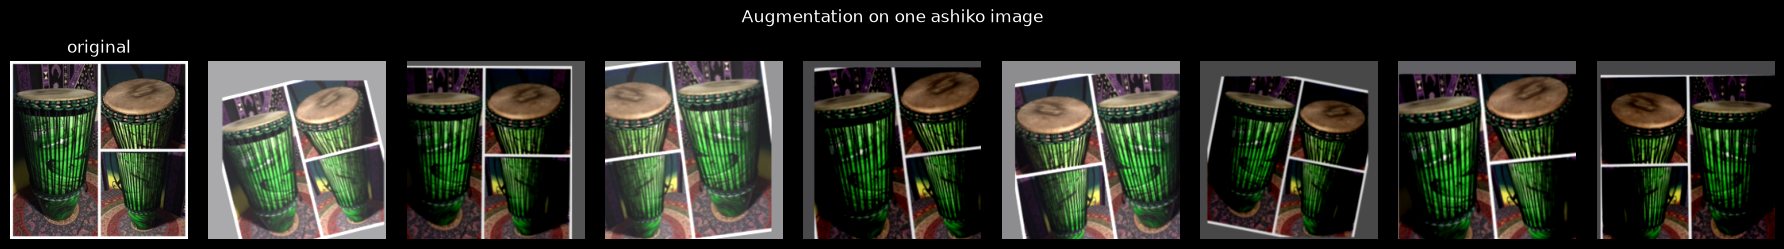

In [5]:
augmenter = keras.Sequential([
    keras.layers.RandomFlip('horizontal'),
    keras.layers.RandomRotation((-0.04, 0.04), fill_mode='constant', fill_value=PAD_FILL),                        # about +-14 degrees
    keras.layers.RandomZoom((-0.15, 0.15), fill_mode='constant', fill_value=PAD_FILL),
    keras.layers.RandomTranslation(0.1, 0.1, fill_mode='constant', fill_value=PAD_FILL),
    keras.layers.RandomBrightness(0.2, value_range=(0, 255)),
    keras.layers.RandomContrast(0.2, value_range=(0, 255)),
])


def augment(images, batch=128):
    out = np.empty_like(images)
    for start in range(0, len(images), batch):
        chunk = images[start:start + batch].astype('float32')
        out[start:start + batch] = np.clip(np.round(keras.ops.convert_to_numpy(augmenter(chunk, training=True))), 0, 255).astype('uint8')
    return out


# What the transforms do to one image: the original, then eight augmented versions
sample = X_train[np.where(y_train == 0)[0][0]]
versions = augment(np.repeat(sample[None], 8, axis=0))
fig, axes = plt.subplots(1, 9, figsize=(18, 2.4))
for ax, img, title in zip(axes, [sample, *versions], ['original'] + [''] * 8):
    ax.imshow(img); ax.set_title(title); ax.axis('off')
plt.suptitle(f'Augmentation on one {class_names[0]} image', y=1.02)
plt.tight_layout()
plt.show()

In [6]:
# The training set: every balanced slot, plus AUG_COPIES augmented versions of it
X_bal = X_train[bal_idx]
first = X_bal.copy()
first[is_extra] = augment(X_bal[is_extra])         # a repeated draw is only kept in augmented form
X_aug = np.concatenate([first] + [augment(X_bal) for _ in range(AUG_COPIES)])
y_aug = np.tile(y_bal, 1 + AUG_COPIES)

del X_bal, first
assert (np.bincount(y_aug, minlength=n_classes) == target * (1 + AUG_COPIES)).all()
print(f'{len(X_train)} original training images -> {len(X_aug)} after balancing and augmenting ({target * (1 + AUG_COPIES)} per class)')
print(f'test set untouched: {len(X_test)} images')

1794 original training images -> 4000 after balancing and augmenting (500 per class)
test set untouched: 449 images


### 3.3 Embed

Each application, loaded with `include_top=False, pooling='avg'`, turns an image into one embedding vector. Before an image goes in, it passes through that application's own `preprocess_input` (section 1.1). The balanced, augmented training set and the untouched test set are both embedded, and **every application sees exactly the same training images**, so any difference between them comes from the application and not from the data it was given.

The helper below embeds in chunks so the whole float32 training set never has to sit in memory at once. Each application's embedding is computed inside its own section, so its time can be reported.

In [7]:
def embed(keras_app, preprocess, images, chunk=256):
    out = []
    for start in range(0, len(images), chunk):
        batch = preprocess(images[start:start + chunk].astype('float32'))      # astype copies, so the originals are never altered
        out.append(keras_app.predict(batch, batch_size=32, verbose=0))
    return np.concatenate(out)


# Embedding is by far the slowest step (minutes), so the result is cached on disk, outside the repo. The cache is only
# reused when it was made from exactly these images, size and weights; anything else is re-embedded automatically.
EMB_DIR = PROC_DIR / 'embeddings'
EMB_DIR.mkdir(exist_ok=True)
FINGERPRINT = hashlib.md5(X_aug[::37].tobytes() + X_test[::11].tobytes() + str((X_aug.shape, X_test.shape, IMG_SIZE, WEIGHTS, SEED, AUG_COPIES)).encode()).hexdigest()


def get_embeddings(key, keras_app, preprocess):
    path = EMB_DIR / f'{key}.npz'
    if path.exists():
        saved = np.load(path)
        if str(saved['fingerprint']) == FINGERPRINT:
            return saved['E_train'], saved['E_test'], float(saved['embed_seconds']), True
    start = time.perf_counter()
    E_train = embed(keras_app, preprocess, X_aug)
    E_test = embed(keras_app, preprocess, X_test)
    seconds = time.perf_counter() - start
    np.savez(path, E_train=E_train, E_test=E_test, embed_seconds=seconds, fingerprint=FINGERPRINT)
    return E_train, E_test, seconds, False

## 4. The linear probe

The model we train is a `Sequential` with a **single `Dense` output layer**: one unit per class, `softmax` activation, taking the embedding vector as input. That is a linear probe. It has no hidden layer, so it can only draw straight boundaries between classes in embedding space; if the classes are separable at all, it is the embedding that made them so, which is exactly what we want to compare.

**Identical for every application.** Optimizer (Adam), learning rate (0.001), batch size (200) and epochs (500) are the same for all three probes, and only the input size changes, to match each application's embedding length. Those are the settings `U2-2_CNN-6_TransferLearning` uses. Any accuracy difference therefore comes from the application, not from how hard we trained the probe on top of it.

**No early stopping.** The course notebook stops training when a validation score stops improving, but a stopping rule needs a validation set that is not the test set, and we have only train and test. Rather than let the test set influence training, we fix 500 epochs for everyone and check in section 8.2 that every loss curve has levelled off. A first run at 50 epochs was still improving, most of all for the largest application, which would have made the comparison partly a test of which probe trains fastest. The probe is a single layer on cached embeddings, so the extra epochs cost seconds.

The embeddings are used as they come out of the application, with no standardizing step. Notebook 4 and the app join the application and the probe into one model, and that joined model has nowhere to put a scaler.

In [8]:
def build_probe(embedding_dim):
    return keras.Sequential([
        keras.Input(shape=(embedding_dim,)),
        keras.layers.Dense(n_classes, activation='softmax'),
    ])


def train_probe(E_train, y_train_):
    probe = build_probe(E_train.shape[1])
    probe.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    start = time.perf_counter()
    history = probe.fit(E_train, y_train_, epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True, verbose=0)
    return probe, history.history, time.perf_counter() - start

### 4.1 One function per application

`run_application` does everything for one application, in order: build it, embed the training and test sets, train the probe, and evaluate on the test set. Each of the next three sections runs it for one model, so each model gets its own header and its own results.

**What the evaluation reports.** Accuracy alone hides a class the model has given up on, and the more classes there are the more that matters, so every application gets accuracy, macro-F1 (the average of the per-class F1 scores, which counts every class equally whatever its size), a full classification report, **per-class recall** (of all the real images of a drum, how many the model found) and a confusion matrix with class names on both axes.

In [9]:
results = {}


def run_application(key):
    cfg = APPLICATIONS[key]
    keras_app = cfg['build']()

    # --- embed: the balanced, augmented training set and the untouched test set
    E_train, E_test, embed_seconds, cached = get_embeddings(key, keras_app, cfg['preprocess'])

    # --- train the probe
    probe, history, train_seconds = train_probe(E_train, y_aug)

    # --- evaluate on the test set
    pred = probe.predict(E_test, verbose=0).argmax(axis=1)
    accuracy = accuracy_score(y_test, pred)
    macro_f1 = f1_score(y_test, pred, average='macro')
    cm = confusion_matrix(y_test, pred, labels=range(n_classes))
    recall = pd.Series(recall_score(y_test, pred, average=None, labels=range(n_classes)), index=class_names)

    print(f"{cfg['name']}: {keras_app.count_params() / 1e6:.1f} M parameters, embedding length {E_train.shape[1]}")
    print(f'embedding time {embed_seconds:.0f} s' + (' (from the cache; this is how long it originally took)' if cached else '') + f', probe training time {train_seconds:.1f} s')
    loss = history['loss']
    print(f'training loss {loss[0]:.3f} -> {loss[-1]:.3f}; change over the last 50 epochs {100 * (loss[-1] / loss[-51] - 1):+.1f}%')
    print(f'test accuracy {accuracy:.3f}, macro-F1 {macro_f1:.3f}\n')
    print(classification_report(y_test, pred, target_names=class_names, digits=3))
    print('Per-class recall, lowest first:')
    print(recall.sort_values().round(3).to_string())

    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
    ax.set_title(f"{cfg['name']}: confusion matrix on the test set")
    plt.tight_layout()
    plt.show()

    return dict(name=cfg['name'], tier=cfg['tier'], params=keras_app.count_params(), embedding_dim=E_train.shape[1],
                embed_seconds=embed_seconds, probe=probe, probe_params=probe.count_params(), train_seconds=train_seconds,
                history=history, accuracy=accuracy, macro_f1=macro_f1, cm=cm, recall=recall, E_test=E_test)

## 5. Model 1: MobileNetV2 (small)

The smallest application and the fastest to run. Its `preprocess_input` scales pixels to [-1, 1].

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2: 2.3 M parameters, embedding length 1280
embedding time 12 s, probe training time 8.7 s
training loss 1.818 -> 0.001; change over the last 50 epochs -37.7%
test accuracy 0.733, macro-F1 0.729

              precision    recall  f1-score   support

      ashiko      0.792     0.764     0.778        55
        bata      0.683     0.549     0.609        51
      bendir      0.862     0.918     0.889        61
  bougarabou      0.739     0.680     0.708        50
      djembe      0.735     0.833     0.781        60
       dunun      0.818     0.789     0.804        57
       sabar      0.524     0.532     0.528        62
talking_drum      0.707     0.774     0.739        53

    accuracy                          0.733       449
   macro avg      0.733     0.730     0.729       449
weighted avg      0.732     0.733     0.731       449

Per-class recall, lowest first:
sabar           0.532
bata            0.549
bougarabou      0.6

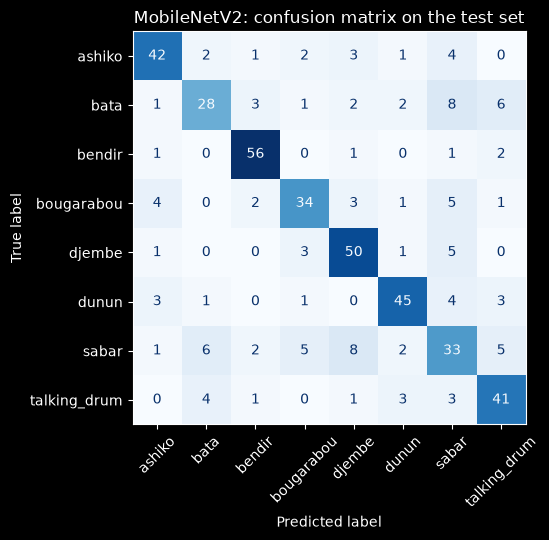

In [10]:
results['mobilenetv2'] = run_application('mobilenetv2')

## 6. Model 2: ResNet50 (medium)

A classic residual network with about seven times as many parameters. Its `preprocess_input` flips RGB to BGR and subtracts the ImageNet channel means.

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
ResNet50: 23.6 M parameters, embedding length 2048
embedding time 35 s, probe training time 9.9 s
training loss 1.722 -> 0.000; change over the last 50 epochs -39.0%
test accuracy 0.746, macro-F1 0.746

              precision    recall  f1-score   support

      ashiko      0.889     0.727     0.800        55
        bata      0.750     0.588     0.659        51
      bendir      0.933     0.918     0.926        61
  bougarabou      0.667     0.720     0.692        50
      djembe      0.774     0.800     0.787        60
       dunun      0.818     0.789     0.804        57
       sabar      0.522     0.581     0.550        62
talking_drum      0.688     0.830     0.752        53

    accuracy                          0.746       449
   macro avg      0.755     0.744     0.746       449
weighted avg      0.756     0.746     0.748       449

Per-class recall, lowest first:
sabar           0.581
bata            0.588
bougarabou      0.7

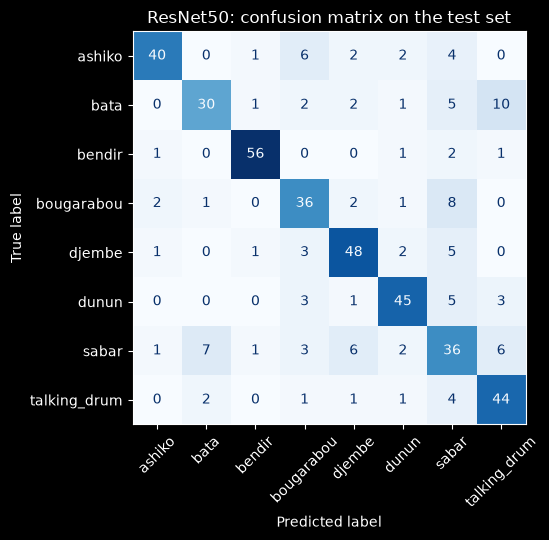

In [11]:
results['resnet50'] = run_application('resnet50')

## 7. Model 3: EfficientNetV2M (large)

The largest of our three. It has rescaling built in and takes raw 0–255 pixels, so its `preprocess_input` leaves the images unchanged. Expect this one to be the slowest to embed.

214201816/214201816 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
EfficientNetV2M: 53.2 M parameters, embedding length 1280
embedding time 71 s, probe training time 8.4 s
training loss 1.885 -> 0.049; change over the last 50 epochs -17.4%
test accuracy 0.710, macro-F1 0.707

              precision    recall  f1-score   support

      ashiko      0.830     0.709     0.765        55
        bata      0.737     0.549     0.629        51
      bendir      0.906     0.951     0.928        61
  bougarabou      0.681     0.640     0.660        50
      djembe      0.716     0.800     0.756        60
       dunun      0.746     0.772     0.759        57
       sabar      0.542     0.516     0.529        62
talking_drum      0.559     0.717     0.628        53

    accuracy                          0.710       449
   macro avg      0.715     0.707     0.707       449
weighted avg      0.716     0.710     0.709       449

Per-class recall, lowest first:
sabar           0.516
bata            0.549
bougarabou

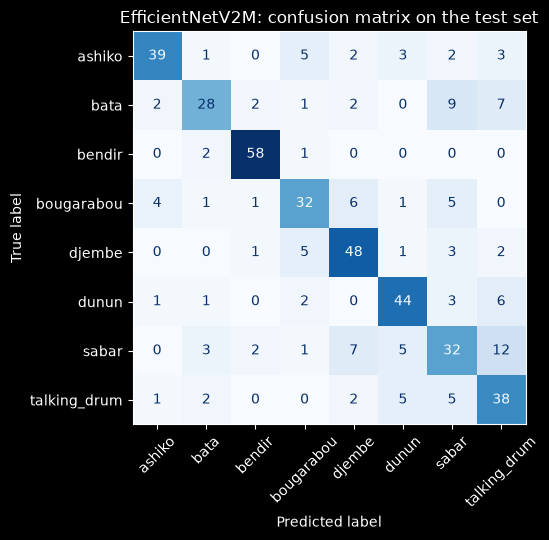

In [12]:
results['effnetv2m'] = run_application('effnetv2m')

## 8. Comparison and discussion

### 8.1 The three applications side by side

One table with everything the central question needs. **Parameters** are those of the application as we used it, without its ImageNet classifier, so they are a little below the appendix figures. **Embedding time** covers the whole training set and the test set, and is by far the largest cost; the probe itself trains in seconds.

In [13]:
summary = pd.DataFrame([{
    'application': r['name'], 'tier': r['tier'], 'parameters (M)': r['params'] / 1e6,
    'embedding length': r['embedding_dim'], 'embedding time (s)': r['embed_seconds'],
    'probe parameters': r['probe_params'], 'probe training time (s)': r['train_seconds'],
    'test accuracy': r['accuracy'], 'macro-F1': r['macro_f1'],
} for r in results.values()]).sort_values('parameters (M)').set_index('application')

summary.round({'parameters (M)': 1, 'embedding time (s)': 0, 'probe training time (s)': 1, 'test accuracy': 3, 'macro-F1': 3})

,tier,parameters (M),embedding length,embedding time (s),probe parameters,probe training time (s),test accuracy,macro-F1
application,,,,,,,,
MobileNetV2,small,2.3,1280,12.0,10248,8.7,0.733,0.729
ResNet50,medium,23.6,2048,35.0,16392,9.9,0.746,0.746
EfficientNetV2M,large,53.2,1280,71.0,10248,8.4,0.710,0.707


### 8.2 Accuracy against size

Test accuracy against parameter count, on a log axis because the sizes span more than an order of magnitude. If bigger always won, the points would climb steadily to the right. A flat or falling line means the extra parameters bought nothing on this dataset.

The right-hand plot is the convergence check promised in section 4: each curve should be flat by the end. If one is still falling, that probe is undertrained and its accuracy understates its application.

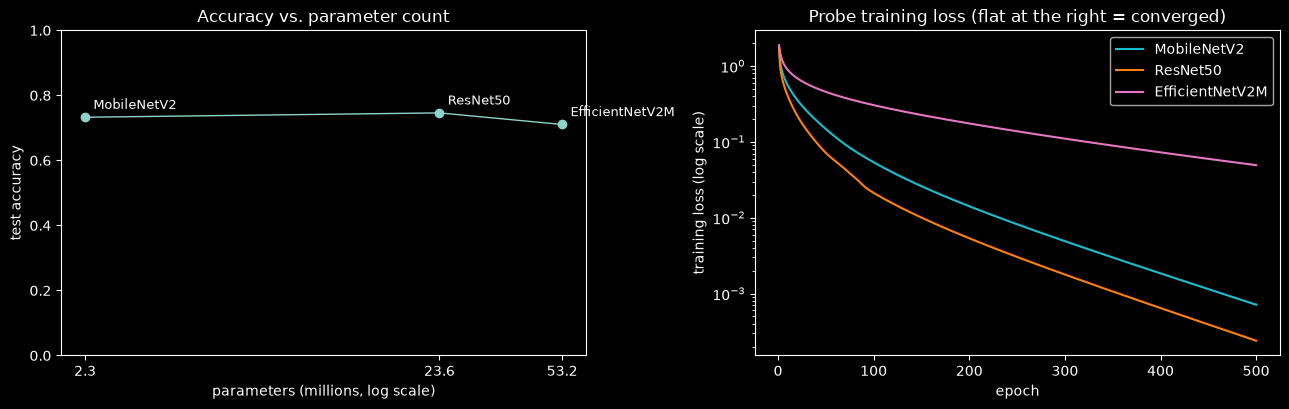

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

ax = axes[0]
ax.plot(summary['parameters (M)'], summary['test accuracy'], marker='o', linewidth=1)
for name, row in summary.iterrows():
    ax.annotate(name, (row['parameters (M)'], row['test accuracy']), textcoords='offset points', xytext=(6, 6), fontsize=9)
ax.set_xscale('log')
ax.set_xticks(summary['parameters (M)'])
ax.set_xticklabels([f'{v:.1f}' for v in summary['parameters (M)']])
ax.minorticks_off()
ax.set_xlabel('parameters (millions, log scale)')
ax.set_ylabel('test accuracy')
ax.set_ylim(0, 1)
ax.set_title('Accuracy vs. parameter count')

ax = axes[1]
for r, color in zip(results.values(), ['tab:cyan', 'tab:orange', 'tab:pink']):
    ax.plot(range(1, EPOCHS + 1), r['history']['loss'], label=r['name'], color=color)
ax.set_xlabel('epoch')
ax.set_yscale('log')
ax.set_ylabel('training loss (log scale)')
ax.set_title('Probe training loss (flat at the right = converged)')
ax.legend()

plt.tight_layout()
plt.show()

### 8.3 What the extra size cost and what it bought

Each larger application measured against the smallest one: accuracy gained, and the multiple of parameters and embedding time paid for it. The last lines also check the suspicious-result warning from the assignment: a test accuracy at or near 100% on a small scraped dataset usually means the same image sits in both train and test, or that the classes differ by a background artifact instead of the subject.

In [15]:
smallest = summary.iloc[0]
for name, row in summary.iloc[1:].iterrows():
    print(f"{name}: {row['test accuracy'] - smallest['test accuracy']:+.1%} accuracy, "
          f"{row['parameters (M)'] / smallest['parameters (M)']:.0f}x the parameters, "
          f"{row['embedding time (s)'] / smallest['embedding time (s)']:.1f}x the embedding time, "
          f"compared with {summary.index[0]}")

if (summary['test accuracy'] >= 0.98).any():
    print('\nWARNING: a test accuracy at or near 100% is suspicious. Recheck Notebook 2 for duplicates and let Notebook 4 show what the model is looking at.')
else:
    print('\nNo test accuracy is suspiciously close to 100%.')

ResNet50: +1.3% accuracy, 10x the parameters, 3.0x the embedding time, compared with MobileNetV2
EfficientNetV2M: -2.2% accuracy, 24x the parameters, 5.9x the embedding time, compared with MobileNetV2

No test accuracy is suspiciously close to 100%.


### 8.4 Revisiting our Notebook 1 prediction

In Notebook 1, before any modeling, we predicted that **`djembe` and `ashiko` would be confused most**, followed by `sabar` / `bougarabou`, then `dunun` / `bata`. Below, every pair of classes is ranked by how often the model confused one for the other (in either direction), and we look up where our predicted pair landed for each application.

In [16]:
PREDICTED = [('ashiko', 'djembe'), ('bougarabou', 'sabar'), ('bata', 'dunun')]      # Notebook 1, most-confused first


def ranked_pairs(cm):
    pairs = [(class_names[i], class_names[j], int(cm[i, j] + cm[j, i])) for i in range(n_classes) for j in range(i + 1, n_classes)]
    return sorted(pairs, key=lambda p: -p[2])


rows = []
for r in results.values():
    ranking = ranked_pairs(r['cm'])
    positions = {(a, b): k + 1 for k, (a, b, n) in enumerate(ranking)}
    rows.append({'application': r['name'], 'most confused pair': f'{ranking[0][0]} / {ranking[0][1]}', 'times confused': ranking[0][2],
                 'rank of ashiko / djembe': positions[PREDICTED[0]], 'rank of bougarabou / sabar': positions[PREDICTED[1]],
                 'rank of bata / dunun': positions[PREDICTED[2]]})
pd.DataFrame(rows).set_index('application')

,most confused pair,times confused,rank of ashiko / djembe,rank of bougarabou / sabar,rank of bata / dunun
application,,,,,
MobileNetV2,bata / sabar,14,11,4,15
ResNet50,bata / sabar,12,12,3,20
EfficientNetV2M,sabar / talking_drum,17,16,9,22


### 8.5 Discussion

**Does bigger win?** No. Accuracy is roughly flat from MobileNetV2 (0.733) to ResNet50 (0.746) and then falls for EfficientNetV2M (0.710). With 449 test images, one point is about 4.5 images, so the gaps between the three applications are within the noise we would expect.

**Where do the returns flatten, and was the largest application worth it?** The returns flatten right away, between MobileNetV2 and ResNet50: ResNet50 gained only 1.3 points for 10 times the parameters and 3 times the embedding time. EfficientNetV2M was not worth its cost. It took 71 s to embed (5.9 times MobileNetV2) and scored lowest, and because Notebook 4 and the app run every model on every upload, it would also be the slowest to use. One caution is that its probe may be slightly undertrained, since its training loss ended at 0.049 and was still falling by 17% over the last 50 epochs, while the other two reached about 0.001 or lower. That could understate its accuracy a little.

**Which classes are weakest?** Almost always the same ones. sabar and bata have the lowest recall in all three applications (0.52 to 0.59), followed by bougarabou (0.64 to 0.72). bendir is the best in all three (0.92 to 0.95), which fits its round frame shape being unlike the other seven drums.

**Was our predicted pair the one that got confused?** No. We predicted ashiko / djembe, but it ranked only 11th, 12th and 16th of 28 pairs. The most-confused pair was bata / sabar for MobileNetV2 and ResNet50 and sabar / talking_drum for EfficientNetV2M, so the mix-ups involve sabar and bata rather than the goblet-shaped pairs we expected. Our guess is that sabar and bata contain many photos of people and performances instead of the drum alone (see Notebook 2), but we have not tested this, and we will look at it with the saliency and Grad-CAM maps in Notebook 4.

## 9. Export

Each trained probe is saved to `models/` as `P2_N3_<application>.keras`. The application name in the filename is how Notebook 4 and the app know which Keras application to rebuild (with `include_top=False, pooling='avg'` and the same weights) and join to each probe. Only the probe is saved, not the application: the application's pretrained weights never changed, and each probe is a few thousand parameters against tens of millions, which keeps every file far below GitHub's 100 MB limit, so **no Git LFS is needed**.

The label-to-index mapping goes next to them, so Notebook 4 and the app read the exact mapping the probes were trained with.

In [17]:
for key, r in results.items():
    r['probe'].save(MODELS_DIR / f'P2_N3_{key}.keras')
(MODELS_DIR / 'P2_N3_label_to_index.json').write_text(json.dumps(label_to_index, indent=2))

# Read every saved probe back and confirm it predicts exactly what the one in memory does
for key, r in results.items():
    reloaded = keras.models.load_model(MODELS_DIR / f'P2_N3_{key}.keras')
    assert np.allclose(reloaded.predict(r['E_test'], verbose=0), r['probe'].predict(r['E_test'], verbose=0), atol=1e-5)
assert json.loads((MODELS_DIR / 'P2_N3_label_to_index.json').read_text()) == label_to_index

for path in sorted(MODELS_DIR.glob('P2_N3_*')):
    print(f'{path.name:<34} {path.stat().st_size / 1e3:8.1f} KB')

P2_N3_effnetv2m.keras                 139.0 KB
P2_N3_label_to_index.json               0.1 KB
P2_N3_mobilenetv2.keras               138.9 KB
P2_N3_resnet50.keras                  212.7 KB


## Review

This notebook compared three pretrained Keras applications of different sizes on our drum dataset:

1. **The applications** are `MobileNetV2` (small), `ResNet50` (medium) and `EfficientNetV2M` (large), each with its own `preprocess_input`: [-1, 1], BGR with mean subtraction, and raw 0–255
2. **The training set** was balanced by oversampling, then augmented with drum-appropriate transforms, then embedded, in that order and on the training set only; the test set was only embedded
3. **The probe** is one `Dense` softmax layer, trained with identical settings for every application, so differences in accuracy come from the application
4. **Evaluation** gave accuracy, macro-F1, a full classification report, per-class recall and a confusion matrix for every application
5. **The comparison** set accuracy against parameter count and embedding time, and checked our Notebook 1 prediction against the confusion matrices
6. **The export** saved each probe to `models/` with the label-to-index mapping

**Next:** `P2_Images-4_xAI.ipynb` rebuilds each application, joins it to its probe, and uses saliency maps and Grad-CAM to see what the models actually look at, including a hunt for shortcuts.